# BGL log anomaly detection and alerting

**Research questions**
- **RQ1:** Does a parser-free representation match or outperform Drain-template representations for semi-supervised and unsupervised anomaly detection?
- **RQ2:** How do training methods (semi-supervised vs unsupervised) and data splitting (chronological vs random) affect detection performance over the seven-month log?
- **RQ3:** Can window-level anomalies be turned into interpretable natural-language alerts that correctly identify the root-cause message?

## Imports and Root Folder

In [2]:
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import os
import random
import re
import shutil
import time
import urllib.request
import warnings
import zipfile

from drain3 import TemplateMiner
from drain3.masking import MaskingInstruction
from drain3.template_miner_config import TemplateMinerConfig
from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import scipy.sparse as sp
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ROOT = Path.cwd()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
print("Repository root:", ROOT)

Repository root: /Users/shreyabharat/Projects/COS802-Project


## 0. Configuration

In [3]:
SMOKE_TEST = False        # True = quick check on the first 300k lines
REUSE_EXISTING = True     # True = skip download / parse / NLP / windows if their outputs already exist

SEED = 42

# Data: Loghub v8 on Zenodo (record 8196385), CC BY 4.0
BGL_URL = "https://zenodo.org/records/8196385/files/BGL.zip?download=1"
BGL_ZIP, BGL_LOG = "BGL.zip", "BGL.log"
EXPECTED_LINES = 4_747_963
MAX_LINES = None                   # e.g. 500_000 for a quicker partial run

# Parsing and windows
DRAIN = {"sim_th": 0.5, "depth": 4, "max_children": 100}
WINDOW_MINUTES = 5
TRAIN_FRAC, VAL_FRAC = 0.7, 0.15   

# NLP preprocessing
SPACY_MODEL = "en_core_web_sm"
MIN_TOKEN_LEN = 2
PROTECTED_WORDS = {"data", "rts", "ciod", "ddr", "tlb", "ras", "iar", "dear", "cpu", "rbs"}

# Representations (RQ1 fair pairs: tfidf vs pf_tfidf, sbert vs pf_sbert)
FEATURE_SETS = ["count", "tfidf", "sbert", "pf_tfidf", "pf_sbert"]
NOVELTY_FEATURE = True
TFIDF_MAX_FEATURES = 2000
SBERT_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
ENCODER_BACKEND = "sentence-transformers"     

# Detectors and training regimes
MODELS = ["iforest", "autoencoder", "pca"]
REGIMES = ["unsupervised", "semi_supervised"]
IFOREST = {"n_estimators": 300, "max_samples": 256}
AUTOENCODER = {"hidden": [256, 64], "latent": 16, "epochs": 25, "batch_size": 256, "lr": 1e-3, "patience": 5}
PCA_VARIANCE = 0.95 # keep the components that explain 95% of the variance
SUPERVISED_REFERENCE = True # logistic regression trained WITH labels: a ceiling, never a method

SEEDS = [42, 43, 44, 45, 46]    # RQ1: seeds for isolation forest and the autoencoder
SPLIT_MODELS = ["iforest", "supervised_ref"]    # RQ2: the supervised model is the control
SPLIT_SEEDS = [42, 43, 44]
MIN_EFFECT = 0.01    # smallest AUC-PR difference treated as meaningful

ALERT_TOP_K, ALERT_EXAMPLES = 3, 25

if SMOKE_TEST:
    MAX_LINES = 300_000
    ENCODER_BACKEND = "hashing"
    AUTOENCODER["epochs"] = 5
    SEEDS, SPLIT_SEEDS = [42, 43], [42, 43]

OUT = ROOT / "smoke" if SMOKE_TEST else ROOT
RAW = ROOT / "data" / "raw"
INTERIM = OUT / "data" / "interim"
PROCESSED = OUT / "data" / "processed"
RESULTS = OUT / "results"
FIGURES = OUT / "reports" / "figures"
TABLES_DIR = OUT / "reports" / "tables"
for folder in (RAW, INTERIM, PROCESSED, RESULTS, FIGURES, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Feature sets:", FEATURE_SETS, "| detectors:", MODELS, "| outputs:", OUT)

Feature sets: ['count', 'tfidf', 'sbert', 'pf_tfidf', 'pf_sbert'] | detectors: ['iforest', 'autoencoder', 'pca'] | outputs: /Users/shreyabharat/Projects/COS802-Project


## 1. Utility functions

In [4]:
# Prints a message with the time, showing how a long run is progressing
def log(msg: str) -> None:
    print(f"{datetime.now():%H:%M:%S} | {msg}", flush=True)

# Shows how long it took to execute a block of code
@contextmanager
def timer(msg: str):
    t0 = time.perf_counter()
    log(f"{msg} ...")
    yield
    log(f"{msg} done in {time.perf_counter() - t0:.1f}s")

# Sets the random seed for Python, Numpy, and PyTorch to the selected random seed for reproducibility
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except ImportError:
        pass

# Assisting with running locally vs on Colab
def get_device() -> str:
    import torch
    if torch.backends.mps.is_available():
        return "mps"
    if torch.cuda.is_available():
        return "cuda"
    return "cpu"

## 2. Download BGL Dataset

In [5]:
def download_bgl() -> Path:
    log_path, zip_path = RAW / BGL_LOG, RAW / BGL_ZIP
    if log_path.exists():
        log(f"{BGL_LOG} already present - skipping download")
    else:
        if not zip_path.exists():
            log(f"Downloading {BGL_URL}")
            req = urllib.request.Request(BGL_URL, headers={"User-Agent": "Mozilla/5.0 (research download)"})
            with urllib.request.urlopen(req) as resp, open(zip_path, "wb") as out:
                total = int(resp.headers.get("Content-Length", 0)) or None
                with tqdm(total=total, unit="B", unit_scale=True, desc=BGL_ZIP) as bar:
                    while chunk := resp.read(1 << 20):
                        out.write(chunk)
                        bar.update(len(chunk))
        log(f"Extracting {BGL_ZIP}")
        with zipfile.ZipFile(zip_path) as zf:
            member = next(m for m in zf.namelist() if m.endswith(BGL_LOG))
            with zf.open(member) as src, open(log_path, "wb") as dst:
                shutil.copyfileobj(src, dst, length=1 << 24)

    n_lines, h = 0, hashlib.sha256()
    with open(log_path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 24), b""):
            n_lines += chunk.count(b"\n")
            h.update(chunk)
    log(f"{BGL_LOG}: {n_lines:,} lines, {log_path.stat().st_size / 1e6:,.0f} MB, sha256={h.hexdigest()[:16]}...")
    if abs(n_lines - EXPECTED_LINES) > 1:
        log(f"WARNING: expected {EXPECTED_LINES:,} lines - check the download")
    return log_path

In [6]:
# Run the download, or check if file already exists
with timer("download"):
    download_bgl()

10:19:58 | download ...
10:19:58 | BGL.log already present - skipping download
10:19:59 | BGL.log: 4,747,963 lines, 743 MB, sha256=666130b15ef44eb3...
10:19:59 | download done in 0.7s


## 3. Parsing (Drain3 template vs parser-free view)

In [ ]:
FIELDS = ["label", "ts", "date", "node", "time", "node_repeat", "type", "component", "level", "content"]
MASKS = [
    (r"R\d+-M\d+(?:-[A-Z0-9]+)*(?::J\d+-U\d+)?", "NODE"),
    (r"\b\d{1,3}(?:\.\d{1,3}){3}(?::\d+)?\b", "IP"),
    (r"\b0x[0-9a-fA-F]+\b", "HEX"),
    (r"\b[0-9a-fA-F]{8,}\b", "HEX"),
    (r"(?:/[\w.\-]+){2,}", "PATH"),
    (r"(?<![A-Za-z_])[-+]?\d+(?:\.\d+)?(?![A-Za-z_])", "NUM"),
]
COMPILED_MASKS = [(re.compile(pattern), f"<{name}>") for pattern, name in MASKS]

def mask_text(content: str) -> str:
    """Parser-free view: apply the regex masks and nothing else."""
    for rx, placeholder in COMPILED_MASKS:
        content = rx.sub(placeholder, content)
    return re.sub(r"\s+", " ", content).strip()

def split_line(line: str) -> dict | None:
    """Split one raw BGL line into its fields. Returns None for malformed lines."""
    parts = line.rstrip("\n").split(maxsplit=9)
    if len(parts) < 9:
        return None
    if len(parts) == 9: # a line with an empty message
        parts.append("")
    rec = dict(zip(FIELDS, parts))
    try:
        rec["ts"] = int(rec["ts"])
    except ValueError:
        return None
    return rec

def make_miner() -> TemplateMiner:
    """A Drain3 template miner that uses the same masks as the parser-free view."""
    c = TemplateMinerConfig()
    c.drain_sim_th, c.drain_depth, c.drain_max_children = DRAIN["sim_th"], DRAIN["depth"], DRAIN["max_children"]
    c.masking_instructions = [MaskingInstruction(pattern, name) for pattern, name in MASKS]
    c.profiling_enabled = False
    return TemplateMiner(config=c)

In [8]:
# parse_bgl() reads the log once, line by line, and for each line:
# 1. splits the fields
# 2. passes the message to Drain3 and records the template id (cluster_id)
# 3. masks the message and gives each distinct masked text an id (msg_id)
# 4. writes the results to data/interim/bgl_parsed.parquet 

def parse_bgl() -> None:
    miner = make_miner()
    schema = pa.schema([
        ("line_id", pa.int64()), ("label", pa.string()), ("is_anomaly", pa.bool_()), ("ts", pa.int64()),
        ("node", pa.string()), ("component", pa.string()), ("level", pa.string()),
        ("content", pa.string()), ("cluster_id", pa.int32()), ("msg_id", pa.int32()),
    ])
    writer = pq.ParquetWriter(INTERIM / "bgl_parsed.parquet", schema, compression="zstd")
    rows, msg_ids, msg_counts, n_bad = [], {}, [], 0
    t_start = time.perf_counter()

    with open(RAW / BGL_LOG, encoding="utf-8", errors="replace") as fh:
        for i, line in enumerate(tqdm(fh, total=MAX_LINES or EXPECTED_LINES, desc="parsing", mininterval=5)):
            if MAX_LINES and i >= MAX_LINES:
                break
            rec = split_line(line)
            if rec is None:
                n_bad += 1
                continue
            cluster_id = miner.add_log_message(rec["content"])["cluster_id"]     # template-based view
            msg_id = msg_ids.setdefault(mask_text(rec["content"]), len(msg_ids))  # parser-free view
            if msg_id == len(msg_counts):
                msg_counts.append(0)
            msg_counts[msg_id] += 1
            rows.append({"line_id": i, "label": rec["label"], "is_anomaly": rec["label"] != "-", "ts": rec["ts"],
                         "node": rec["node"], "component": rec["component"], "level": rec["level"],
                         "content": rec["content"], "cluster_id": cluster_id, "msg_id": msg_id})
            if len(rows) >= 200_000:
                writer.write_table(pa.Table.from_pylist(rows, schema=schema))
                rows.clear()
    if rows:
        writer.write_table(pa.Table.from_pylist(rows, schema=schema))
    writer.close()

    templates = pd.DataFrame([{"cluster_id": c.cluster_id, "template": c.get_template(), "size": c.size}
                              for c in miner.drain.clusters]).sort_values("cluster_id")
    templates.to_csv(INTERIM / "templates.csv", index=False)
    messages = pd.DataFrame({"msg_id": range(len(msg_ids)), "template": list(msg_ids), "size": msg_counts})
    messages.to_csv(INTERIM / "messages.csv", index=False)

    stats = {"lines": int(sum(msg_counts)), "malformed": n_bad, "templates": len(templates),
             "masked_messages": len(messages), "wall_seconds": round(time.perf_counter() - t_start, 1)}
    (INTERIM / "parse_stats.json").write_text(json.dumps(stats, indent=2))
    log(f"Parsed {stats['lines']:,} lines ({n_bad} malformed skipped): {len(templates)} templates, "
        f"{len(messages):,} masked messages")

In [9]:
if REUSE_EXISTING and (INTERIM / "bgl_parsed.parquet").exists():
    print("Parsed data found - skipping. Set REUSE_EXISTING = False to parse again.")
else:
    with timer("parse (Drain3 + masking)"):
        parse_bgl()
print(json.dumps(json.loads((INTERIM / "parse_stats.json").read_text()), indent=1))

10:54:04 | parse (Drain3 + masking) ...


parsing: 100%|██████████| 4747963/4747963 [01:04<00:00, 73230.52it/s]

10:55:09 | Parsed 4,747,963 lines (0 malformed skipped): 392 templates, 16,107 masked messages
10:55:09 | parse (Drain3 + masking) done in 65.0s
{
 "lines": 4747963,
 "malformed": 0,
 "templates": 392,
 "masked_messages": 16107,
 "wall_seconds": 65.0
}


## 4. NLP preprocessing

In [10]:
MASK_TOKEN = re.compile(r"<[A-Z*]+>")   # <*>, <NUM>, <HEX>, <NODE>, ...
CAMEL = re.compile(r"(?<=[a-z])(?=[A-Z])")  # position between 'ciod' and 'Startup'
NON_ALPHA = re.compile(r"[^A-Za-z]+")

def clean_text(template: str) -> str:
    t = MASK_TOKEN.sub(" ", template)
    t = CAMEL.sub(" ", t)
    t = re.sub(r"[_:=\[\](){},;]+", " ", t)
    t = re.sub(r"\.{2,}", " ", t)   # 'enabled.....' -> 'enabled'
    return re.sub(r"\s+", " ", t).strip(" .")

def tokenize(template: str) -> list[str]:
    t = MASK_TOKEN.sub(" ", template)
    t = CAMEL.sub(" ", t)
    return [tok.lower() for tok in NON_ALPHA.split(t) if tok]

def preprocess(table: pd.DataFrame) -> pd.DataFrame:
    import spacy
    nlp = spacy.load(SPACY_MODEL, disable=["parser", "ner"])
    table = table.copy()
    table["clean"] = table["template"].map(clean_text)
    table["tokens"] = table["template"].map(tokenize)
    table["lemmas"] = [
        [tok.lower_ if tok.lower_ in PROTECTED_WORDS else tok.lemma_.lower() for tok in doc
         if not tok.is_stop and tok.is_alpha and len(tok) >= MIN_TOKEN_LEN]
        for doc in nlp.pipe((" ".join(toks) for toks in table["tokens"]), batch_size=256)
    ]
    vocab_tok = len({t for ts in table["tokens"] for t in ts})
    vocab_lem = len({t for ts in table["lemmas"] for t in ts})
    log(f"{len(table):,} rows | vocabulary {vocab_tok} tokens -> {vocab_lem} lemmas")
    return table

def save_table(table: pd.DataFrame, path: Path) -> None:
    out = table.copy()
    out["tokens"], out["lemmas"] = out["tokens"].map(json.dumps), out["lemmas"].map(json.dumps)
    out.to_csv(path, index=False)

def load_table(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, keep_default_na=False)
    df["tokens"], df["lemmas"] = df["tokens"].map(json.loads), df["lemmas"].map(json.loads)
    return df

In [11]:
if REUSE_EXISTING and (INTERIM / "messages_nlp.csv").exists():
    print("NLP outputs found - skipping.")
else:
    with timer("NLP preprocessing"):
        for name in ("templates", "messages"):
            save_table(preprocess(pd.read_csv(INTERIM / f"{name}.csv", keep_default_na=False)),
                       INTERIM / f"{name}_nlp.csv")

11:05:58 | NLP preprocessing ...
11:06:03 | 392 rows | vocabulary 638 tokens -> 506 lemmas
11:06:24 | 16,107 rows | vocabulary 818 tokens -> 672 lemmas
11:06:24 | NLP preprocessing done in 26.5s


## 5. Time windows

In [12]:
SEVERE_LEVELS = {"FATAL", "FAILURE", "SEVERE", "ERROR"}
UNIT_KEYS = {"template": "cluster_id", "message": "msg_id"}   # the id column of each view


def load_lines(columns: list[str]) -> pd.DataFrame:
    """Parsed lines in time order (ties broken by original line number)."""
    df = pd.read_parquet(INTERIM / "bgl_parsed.parquet", columns=["line_id", *columns])
    return df.sort_values(["ts", "line_id"], kind="stable").reset_index(drop=True)


def build_windows(lines: pd.DataFrame, tables: dict) -> tuple[pd.DataFrame, dict]:
    size = WINDOW_MINUTES * 60
    ts = lines["ts"].to_numpy()
    t0 = int(ts.min())
    win = (ts - t0) // size # window number of every line
    n_windows = int(win.max()) + 1

    counts = {}
    for unit, key in UNIT_KEYS.items():
        col_of = pd.Series(np.arange(len(tables[unit])), index=tables[unit][key].values)
        cols = col_of.reindex(lines[key].values).to_numpy()
        assert not np.isnan(cols).any(), f"some {key} values are missing from the {unit} table"
        counts[unit] = sp.csr_matrix((np.ones(len(lines), dtype=np.float32), (win, cols.astype(np.int64))),
                                     shape=(n_windows, len(tables[unit])))     # duplicates are summed

    per_window = lambda values: np.bincount(win, weights=values, minlength=n_windows)
    node_codes = pd.factorize(lines["node"])[0].astype(np.int64)
    pairs = np.unique(win * (node_codes.max() + 1) + node_codes)    # distinct (window, node) pairs
    meta = pd.DataFrame({
        "win_id": np.arange(n_windows),
        "start_ts": t0 + np.arange(n_windows) * size,
        "n_lines": per_window(np.ones(len(lines))).astype(int),
        "n_anom_lines": per_window(lines["is_anomaly"].to_numpy().astype(float)).astype(int),
        "n_severe_lines": per_window(lines["level"].isin(SEVERE_LEVELS).to_numpy().astype(float)).astype(int),
        "n_nodes": np.bincount(pairs // (node_codes.max() + 1), minlength=n_windows).astype(int),
    })
    meta["end_ts"] = meta["start_ts"] + size
    meta["label"] = (meta["n_anom_lines"] > 0).astype(int)

    keep = meta["n_lines"].to_numpy() >= 1  # drop empty windows
    meta = meta[keep].reset_index(drop=True)
    counts = {unit: m[np.flatnonzero(keep)].tocsr() for unit, m in counts.items()}
    log(f"{len(meta):,} windows kept ({(~keep).sum():,} empty dropped); anomalous windows {meta['label'].mean():.1%}; "
        f"line-level anomaly rate {lines['is_anomaly'].mean():.2%}")
    return meta, counts


def assign_split(n: int, mode: str = "chronological", seed: int = SEED) -> np.ndarray:
    """'train' / 'val' / 'test' for each of n windows (which are in time order)."""
    order = np.arange(n) if mode == "chronological" else np.random.default_rng(seed).permutation(n)
    n_train, n_val = int(n * TRAIN_FRAC), int(n * VAL_FRAC)
    split = np.empty(n, dtype=object)
    split[order[:n_train]] = "train"
    split[order[n_train:n_train + n_val]] = "val"
    split[order[n_train + n_val:]] = "test"
    return split

In [13]:
if REUSE_EXISTING and (PROCESSED / "windows.parquet").exists():
    print("Windows found - skipping. Set REUSE_EXISTING = False to rebuild.")
else:
    with timer("windowing"):
        _tables = {"template": load_table(INTERIM / "templates_nlp.csv"),
                   "message": load_table(INTERIM / "messages_nlp.csv")}
        _meta, _counts = build_windows(load_lines(["ts", "cluster_id", "msg_id", "is_anomaly", "level", "node"]), _tables)
        _meta.to_parquet(PROCESSED / "windows.parquet", index=False)
        for unit, m in _counts.items():
            sp.save_npz(PROCESSED / f"W_{unit}.npz", m)

20:56:55 | windowing ...
20:56:56 | 14,501 windows kept (47,339 empty dropped); anomalous windows 7.3%; line-level anomaly rate 7.34%
20:56:56 | windowing done in 1.6s


## 6. Sanity Checks

In [14]:
NORMAL = ("- 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.675872 "
          "R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected")
ALERT = ("KERNDTLB 1117869872 2005.06.04 R23-M0-N6-C:J17-U01 2005-06-04-00.24.32.432099 "
         "R23-M0-N6-C:J17-U01 RAS KERNEL FATAL data TLB error interrupt")

rec = split_line(NORMAL)
assert rec["label"] == "-" and rec["ts"] == 1117838570 and rec["level"] == "INFO"
assert rec["content"] == "instruction cache parity error corrected"
assert split_line(ALERT)["label"] == "KERNDTLB" and split_line("garbage line") is None

miner = make_miner()
a = miner.add_log_message("generating core.2275 on node R02-M1-N0-C:J12-U11 addr 0x0b85eee0")
b = miner.add_log_message("generating core.9981 on node R17-M0-N3-C:J05-U01 addr 0x1c00ffee")
assert a["cluster_id"] == b["cluster_id"] and "<NODE>" in b["template_mined"]
assert mask_text("generating core.2275 on R02-M1-N0-C:J12-U11 addr 0x0b85eee0 from 10.0.0.1:8080") == \
    "generating core.<NUM> on <NODE> addr <HEX> from <IP>"
assert tokenize("ciodStartup failed") == ["ciod", "startup", "failed"]
assert "<" not in clean_text("data TLB error interrupt <*>")

_lines = pd.DataFrame({"ts": np.array([0, 10, 400, 410, 1300, 1310]), "cluster_id": [1, 1, 2, 1, 3, 3],
                       "msg_id": [0, 1, 2, 0, 3, 3], "is_anomaly": [False, False, True, False, False, False],
                       "level": ["INFO", "INFO", "FATAL", "INFO", "INFO", "INFO"], "node": ["a", "a", "b", "a", "c", "d"]})
_meta, _counts = build_windows(_lines, {"template": pd.DataFrame({"cluster_id": [1, 2, 3]}),
                                        "message": pd.DataFrame({"msg_id": [0, 1, 2, 3]})})
assert list(_meta["win_id"]) == [0, 1, 4] and list(_meta["label"]) == [0, 1, 0]
assert _counts["template"].toarray().tolist() == [[2, 0, 0], [1, 1, 0], [0, 0, 2]]
assert list(assign_split(10)) == ["train"] * 7 + ["val"] + ["test"] * 2
print("OK - all quick checks passed")

20:58:42 | 3 windows kept (2 empty dropped); anomalous windows 33.3%; line-level anomaly rate 16.67%
OK - all quick checks passed


## 7. Load model data

In [15]:
set_seed(SEED)
meta = pd.read_parquet(PROCESSED / "windows.parquet")
counts = {unit: sp.load_npz(PROCESSED / f"W_{unit}.npz").tocsr() for unit in UNIT_KEYS}
tables = {"template": load_table(INTERIM / "templates_nlp.csv"), "message": load_table(INTERIM / "messages_nlp.csv")}
split = assign_split(len(meta))
y = meta["label"].to_numpy()
lines = load_lines(["ts", "cluster_id", "msg_id", "is_anomaly", "label", "level", "node", "component"])
print(f"{len(lines):,} lines | {len(meta):,} windows | {len(tables['template'])} templates | "
      f"{len(tables['message']):,} masked messages")
print(pd.Series(split).value_counts().to_string())

4,747,963 lines | 14,501 windows | 392 templates | 16,107 masked messages
train    10150
test      2176
val       2175


## 8. EDA Summary

In [16]:
def data_summary() -> dict:
    templates, messages = tables["template"], tables["message"]
    alert_templates = lines.loc[lines["is_anomaly"], "cluster_id"].unique()
    alert_share = lines[lines["cluster_id"].isin(alert_templates)].groupby("cluster_id")["is_anomaly"].mean()
    msgs_per_template = lines.groupby("cluster_id")["msg_id"].nunique()
    summary = {
        "lines": int(len(lines)),
        "anomalous_lines": int(lines["is_anomaly"].sum()),
        "line_anomaly_rate": float(lines["is_anomaly"].mean()),
        "days_spanned": round(float((lines["ts"].max() - lines["ts"].min()) / 86400), 1),
        "first_ts": int(lines["ts"].min()), "last_ts": int(lines["ts"].max()),
        "nodes": int(lines["node"].nunique()),
        "templates": int(len(templates)),
        "templates_with_any_alert_line": int(len(alert_templates)),
        "alert_templates_always_alert": int((alert_share == 1.0).sum()),
        "alert_categories": lines.loc[lines["is_anomaly"], "label"].value_counts().head(15).to_dict(),
        "level_by_label": pd.crosstab(lines["level"], lines["is_anomaly"]).to_dict(),
        "vocab_raw_tokens": int(len({t for ts in templates["tokens"] for t in ts})),
        "vocab_lemmas": int(len({t for ts in templates["lemmas"] for t in ts})),
        "masked_messages": int(len(messages)),
        "masked_messages_per_template_median": float(msgs_per_template.median()),
        "masked_messages_per_template_max": int(msgs_per_template.max()),
        "lines_per_masked_message_median": float(messages["size"].median()),
        "windows": int(len(meta)),
        "window_anomaly_rate": float(meta["label"].mean()),
        "median_lines_per_window": float(meta["n_lines"].median()),
    }
    (RESULTS / "eda_summary.json").write_text(json.dumps(summary, indent=2, default=str))
    return summary


eda = data_summary()
pd.Series({k: v for k, v in eda.items() if not isinstance(v, dict)}, name="value").to_frame()

,value
lines,4.747963e+06
anomalous_lines,3.484600e+05
line_anomaly_rate,7.339147e-02
days_spanned,2.147000e+02
first_ts,1.117839e+09
last_ts,1.136390e+09
nodes,6.925200e+04
templates,3.920000e+02
templates_with_any_alert_line,5.500000e+01
alert_templates_always_alert,4.500000e+01


## 9. Sentence encoder

In [17]:
def hashing_encode(texts: list[str], dim: int = 384) -> np.ndarray:
    """Offline stand-in: signed hashing of character trigrams, L2-normalised. Smoke tests only."""
    out = np.zeros((len(texts), dim), dtype=np.float32)
    for i, t in enumerate(texts):
        t = f"  {t.lower()}  "
        for j in range(len(t) - 2):
            h = int(hashlib.md5(t[j:j + 3].encode()).hexdigest()[:8], 16)
            out[i, h % dim] += 1.0 if (h >> 31) & 1 else -1.0
    norms = np.linalg.norm(out, axis=1, keepdims=True)
    return out / np.where(norms == 0, 1, norms)


def embeddings(unit: str) -> np.ndarray:
    """One vector per template (unit='template') or per masked message (unit='message'), cached on disk."""
    table = tables[unit]
    prefix = {"template": "sbert_template", "message": "pf_sbert_message"}[unit]
    cache = PROCESSED / f"{prefix}_{ENCODER_BACKEND}_emb.npy"
    if cache.exists() and np.load(cache).shape[0] == len(table):
        return np.load(cache)
    texts = [t if t else "empty" for t in table["clean"]]
    if ENCODER_BACKEND == "hashing":
        log("Using the offline HASHING encoder - smoke tests only, do not report these numbers")
        E = hashing_encode(texts)
    else:
        from sentence_transformers import SentenceTransformer
        model = SentenceTransformer(SBERT_MODEL, device=get_device())
        E = model.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    E = E.astype(np.float32)
    np.save(cache, E)
    return E

## 10. Feature extraction

In [18]:
UNIT_OF = {"count": "template", "tfidf": "template", "sbert": "template", "pf_tfidf": "message", "pf_sbert": "message"}
PARSER_FREE = {"pf_tfidf", "pf_sbert"}


def pool(C: sp.csr_matrix, E: np.ndarray) -> np.ndarray:
    """Per window: count-weighted mean and max of the vectors (E) of the units it contains."""
    C = C.tocsr()
    row_sums = np.asarray(C.sum(axis=1)).ravel()
    row_sums[row_sums == 0] = 1.0
    mean = np.asarray(sp.diags(1.0 / row_sums) @ C @ E)
    mx = np.zeros_like(mean)
    for i in range(C.shape[0]):
        idx = C.indices[C.indptr[i]:C.indptr[i + 1]]
        if len(idx):
            mx[i] = E[idx].max(axis=0)
    return np.hstack([mean, mx]).astype(np.float32)


def fit_features(fs: str, C_fit: sp.csr_matrix):
    """Learn feature set `fs` from the fit windows' counts. Returns transform(C) -> one feature row per window."""
    table = tables[UNIT_OF[fs]]
    seen = np.asarray(C_fit.sum(axis=0)).ravel() > 0        # message types present in the fit windows

    if fs == "count":
        base = lambda C: np.log1p(C.toarray())
    elif fs in ("tfidf", "pf_tfidf"):
        docs = table["lemmas"].tolist()
        vectorizer = CountVectorizer(analyzer=lambda toks: toks, max_features=TFIDF_MAX_FEATURES)
        vectorizer.fit([d for d, s in zip(docs, seen) if s])  # vocabulary from seen message types only
        T = vectorizer.transform(docs)                        # message type x lemma counts
        tfidf = TfidfTransformer(sublinear_tf=True).fit(C_fit @ T)
        base = lambda C: tfidf.transform(C @ T).toarray()
    else:                                                     # sbert, pf_sbert
        E = embeddings(UNIT_OF[fs])
        base = lambda C: pool(C, E)

    def transform(C: sp.csr_matrix) -> np.ndarray:
        C = C.tocsr()
        X = base(C)
        if NOVELTY_FEATURE:
            unseen_lines = np.asarray(C[:, ~seen].sum(axis=1)).ravel()
            X = np.hstack([X, np.log1p(unseen_lines)[:, None]])
        return X.astype(np.float32)

    return transform

## 11. Detectors

In [19]:
# isolation forest, PCA, autoencoder, and logistic regression (supervised reference)

def train_autoencoder(X: np.ndarray, seed: int):
    import torch
    import torch.nn as nn

    c = AUTOENCODER
    device = get_device()
    torch.manual_seed(seed)
    idx = np.random.default_rng(seed).permutation(len(X))
    n_val = max(1, int(0.1 * len(X)))                         # 10% held out for early stopping
    X_tr = torch.tensor(X[idx[n_val:]], dtype=torch.float32)
    X_va = torch.tensor(X[idx[:n_val]], dtype=torch.float32).to(device)

    sizes = [X.shape[1], *c["hidden"], c["latent"]]           # d -> 256 -> 64 -> 16
    enc, dec = [], []
    for a, b in zip(sizes[:-1], sizes[1:]):
        enc += [nn.Linear(a, b), nn.ReLU()]
    for a, b in zip(sizes[::-1][:-1], sizes[::-1][1:]):       # 16 -> 64 -> 256 -> d
        dec += [nn.Linear(a, b), nn.ReLU()]
    net = nn.Sequential(nn.Sequential(*enc[:-1]), nn.Sequential(*dec[:-1])).to(device)  # no ReLU on the code or output

    opt = torch.optim.Adam(net.parameters(), lr=c["lr"])
    loss_fn = nn.MSELoss()
    best, best_state, wait = np.inf, None, 0
    for epoch in range(c["epochs"]):
        net.train()
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr), c["batch_size"]):
            xb = X_tr[perm[i:i + c["batch_size"]]].to(device)
            opt.zero_grad()
            loss = loss_fn(net(xb), xb)
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = loss_fn(net(X_va), X_va).item()
        if v < best - 1e-5:
            best, wait = v, 0
            best_state = {k: t.detach().clone() for k, t in net.state_dict().items()}
        else:
            wait += 1
            if wait >= c["patience"]:
                break
    net.load_state_dict(best_state)

    def score(X_new: np.ndarray) -> np.ndarray:
        errors = []
        with torch.no_grad():
            for i in range(0, len(X_new), 4096):
                xb = torch.tensor(X_new[i:i + 4096], dtype=torch.float32).to(device)
                errors.append(((net(xb) - xb) ** 2).cpu().numpy())
        return np.vstack(errors).mean(axis=1)

    return score


def train_model(name: str, X: np.ndarray, y_fit, seed: int):
    """Train one detector on standardised features X. Returns score(X) -> higher = more anomalous."""
    if name == "iforest":
        m = IsolationForest(n_estimators=IFOREST["n_estimators"], max_samples=IFOREST["max_samples"],
                            random_state=seed, n_jobs=-1).fit(X)
        return lambda X_new: -m.score_samples(X_new)
    if name == "pca":
        m = PCA(n_components=PCA_VARIANCE, random_state=seed).fit(X)
        return lambda X_new: ((X_new - m.inverse_transform(m.transform(X_new))) ** 2).mean(axis=1)
    if name == "autoencoder":
        return train_autoencoder(X, seed)
    if name == "supervised_ref":
        m = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=seed).fit(X, y_fit)
        return lambda X_new: m.predict_proba(X_new)[:, 1]
    raise ValueError(name)

In [20]:
class Detector:
    def __init__(self, feature_set: str, model: str, seed: int = SEED):
        self.feature_set, self.model, self.seed = feature_set, model, seed

    def fit(self, C_fit: sp.csr_matrix, y_fit=None) -> "Detector":
        self.transform = fit_features(self.feature_set, C_fit)
        self.scaler = StandardScaler()
        X = self.scaler.fit_transform(self.transform(C_fit))
        self.score_fn = train_model(self.model, X, y_fit, self.seed)
        return self

    def score(self, C: sp.csr_matrix) -> np.ndarray:
        return self.score_fn(self.scaler.transform(self.transform(C)).astype(np.float32))


def severity_rule_scores() -> np.ndarray:
    """Baseline that reads the Level field: the number of FATAL / FAILURE / SEVERE / ERROR lines per window."""
    return meta["n_severe_lines"].to_numpy().astype(float)

## 12. Metrics

In [21]:
def best_f1_threshold(y_true: np.ndarray, s: np.ndarray) -> float:
    p, r, thr = precision_recall_curve(y_true, s)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(thr[np.argmax(f1[:-1])]) if len(thr) else float(np.max(s))


def span_days(m: pd.DataFrame) -> float:
    return (m["end_ts"].max() - m["start_ts"].min()) / 86400


def evaluate(y_true: np.ndarray, s: np.ndarray, thr: float, days: float) -> dict:
    pred = (s >= thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    return {"auc_pr": average_precision_score(y_true, s) if y_true.any() else np.nan,
            "precision": p, "recall": r, "f1": f1,
            "false_alarms_per_day": int(((pred == 1) & (y_true == 0)).sum()) / max(days, 1e-9)}

## 13. RQ1: template-based vs parser-free

In [22]:
STOCHASTIC = {"iforest", "autoencoder"}     # detectors whose result depends on the seed
SD_COLS = ["val_auc_pr", "auc_pr", "auc_pr_novel", "precision", "recall", "f1", "false_alarms_per_day"]

def fit_mask(split: np.ndarray, regime: str) -> np.ndarray:
    train = split == "train"
    return train & (y == 0) if regime == "semi_supervised" else train

def novel_windows() -> np.ndarray:
    C = counts["template"]
    unseen = np.asarray(C[split == "train"].sum(axis=0)).ravel() == 0
    return np.asarray(C[:, unseen].sum(axis=1)).ravel() > 0

def score_row(s: np.ndarray, novel: np.ndarray, **ident) -> dict:
    val, test = split == "val", split == "test"
    thr = best_f1_threshold(y[val], s[val])
    row = {**ident, "val_auc_pr": average_precision_score(y[val], s[val]) if y[val].any() else np.nan}
    row.update(evaluate(y[test], s[test], thr, span_days(meta[test])))
    sub = test & novel
    row["n_novel_test_windows"] = int(sub.sum())
    row["auc_pr_novel"] = average_precision_score(y[sub], s[sub]) if 0 < y[sub].sum() < sub.sum() else np.nan
    return row

def average_over_seeds(rows: list[dict]) -> dict:
    df = pd.DataFrame(rows)
    out = {k: v for k, v in rows[0].items() if k != "seed"}
    for col in df.columns:
        if col != "seed" and pd.api.types.is_numeric_dtype(df[col]):
            out[col] = float(df[col].mean())
    for col in SD_COLS:
        if col in df:
            out[f"{col}_sd"] = float(df[col].std(ddof=1)) if len(df) > 1 else 0.0
    out["n_seeds"] = len(df)
    return out

In [23]:
def run_experiments() -> pd.DataFrame:
    novel = novel_windows()
    scores = pd.DataFrame({"win_id": meta["win_id"], "split": split, "label": y})
    rows, seed_rows = [], []

    s = severity_rule_scores()
    scores["severity_rule"] = s
    rows.append(average_over_seeds([score_row(s, novel, feature_set="level_field", representation="baseline",
                                              model="severity_rule", regime="rule")]))

    combos = [(m, r) for m in MODELS for r in REGIMES]
    if SUPERVISED_REFERENCE:
        combos.append(("supervised_ref", "supervised"))

    for fs in FEATURE_SETS:
        C = counts[UNIT_OF[fs]]
        rep = "parser-free" if fs in PARSER_FREE else "template"
        for model, regime in combos:
            key, per_seed, t0 = f"{fs}|{model}|{regime}", [], time.perf_counter()
            for seed in (SEEDS if model in STOCHASTIC else SEEDS[:1]):
                set_seed(seed)
                det = Detector(fs, model, seed)
                if regime == "supervised":
                    det.fit(C[split == "train"], y[split == "train"])
                else:
                    det.fit(C[fit_mask(split, regime)])
                s = det.score(C)
                if seed == SEEDS[0]:
                    scores[key] = s
                per_seed.append({**score_row(s, novel, feature_set=fs, representation=rep, model=model,
                                             regime=regime), "seed": seed})
            seed_rows += per_seed
            rows.append(average_over_seeds(per_seed))
            r = rows[-1]
            log(f"{key:<38} AUC-PR {r['auc_pr']:.3f} ± {r['auc_pr_sd']:.3f} | F1 {r['f1']:.3f} | "
                f"{r['n_seeds']} seed(s) | {time.perf_counter() - t0:.1f}s")

    results = pd.DataFrame(rows)
    results.to_csv(RESULTS / "metrics.csv", index=False)
    pd.DataFrame(seed_rows).to_csv(RESULTS / "metrics_seeds.csv", index=False)
    scores.to_parquet(RESULTS / "window_scores.parquet", index=False)
    return results

In [24]:
def plot_results(results: pd.DataFrame, scores: pd.DataFrame) -> None:
    test = scores["split"] == "test"
    y_test = scores.loc[test, "label"].to_numpy()

    fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.2), sharey=True)
    for ax, model in zip(np.atleast_1d(axes), MODELS):
        for fs in FEATURE_SETS:
            col = f"{fs}|{model}|semi_supervised"
            p, r, _ = precision_recall_curve(y_test, scores.loc[test, col])
            ap = results.query("feature_set == @fs and model == @model and regime == 'semi_supervised'")["auc_pr"].iloc[0]
            ax.plot(r, p, label=f"{fs} (AP {ap:.2f})")
        ax.axhline(y_test.mean(), ls="--", c="grey", lw=1, label=f"chance ({y_test.mean():.2f})")
        ax.set(title=f"{model} - semi-supervised", xlabel="Recall", ylim=(0, 1.02))
        ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("Precision")
    fig.tight_layout()
    fig.savefig(FIGURES / "pr_curves_test.png", dpi=160)
    plt.close(fig)

    grid = results[results["regime"].isin(REGIMES)]
    fig, axes = plt.subplots(1, len(REGIMES), figsize=(6 * len(REGIMES), 3.6))
    for ax, regime in zip(np.atleast_1d(axes), REGIMES):
        pv = grid[grid["regime"] == regime].pivot(index="feature_set", columns="model", values="auc_pr")
        pv = pv.reindex(index=FEATURE_SETS, columns=MODELS)
        im = ax.imshow(pv.values, vmin=0, vmax=1, cmap="Blues")
        ax.set_xticks(range(pv.shape[1]), pv.columns)
        ax.set_yticks(range(pv.shape[0]), pv.index)
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                v = pv.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else "black")
        ax.set_title(f"Test AUC-PR - {regime}")
    fig.colorbar(im, ax=axes, shrink=0.8)
    fig.savefig(FIGURES / "auc_pr_grid.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

    best = grid.loc[grid.groupby("feature_set")["val_auc_pr"].idxmax()].set_index("feature_set")
    best = best.reindex([f for f in FEATURE_SETS if f in best.index])
    x = np.arange(len(best))
    colors = ["#a8501f" if f in PARSER_FREE else "#2b5d73" for f in best.index]
    fig, ax = plt.subplots(figsize=(1.4 * len(best) + 2, 3.8))
    ax.bar(x - 0.2, best["auc_pr"], 0.4, yerr=best["auc_pr_sd"].fillna(0), capsize=3, color=colors,
           label="all test windows (mean ± sd over seeds)")
    ax.bar(x + 0.2, best["auc_pr_novel"], 0.4, color=colors, alpha=0.45, hatch="//", label="windows with unseen templates")
    ax.set_xticks(x, [f"{f}\n{r.model[:7]}/{r.regime[:4]}" for f, r in best.iterrows()], fontsize=8)
    ax.set(ylim=(0, 1), ylabel="Test AUC-PR", title="RQ1: template-based (blue) vs parser-free (orange)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES / "rq1_template_vs_parser_free.png", dpi=160)
    plt.close(fig)

21:29:56 | experiments (RQ1) ...
21:29:58 | count|iforest|unsupervised             AUC-PR 0.555 ± 0.016 | F1 0.500 | 5 seed(s) | 1.8s
21:29:59 | count|iforest|semi_supervised          AUC-PR 0.265 ± 0.025 | F1 0.028 | 5 seed(s) | 1.8s
21:30:11 | count|autoencoder|unsupervised         AUC-PR 0.594 ± 0.010 | F1 0.469 | 5 seed(s) | 11.5s
21:30:20 | count|autoencoder|semi_supervised      AUC-PR 0.610 ± 0.006 | F1 0.490 | 5 seed(s) | 9.2s
21:30:20 | count|pca|unsupervised                 AUC-PR 0.630 ± 0.000 | F1 0.254 | 1 seed(s) | 0.1s
21:30:20 | count|pca|semi_supervised              AUC-PR 0.654 ± 0.000 | F1 0.500 | 1 seed(s) | 0.1s
21:30:20 | count|supervised_ref|supervised        AUC-PR 0.695 ± 0.000 | F1 0.713 | 1 seed(s) | 0.2s
21:30:22 | tfidf|iforest|unsupervised             AUC-PR 0.614 ± 0.037 | F1 0.480 | 5 seed(s) | 1.8s
21:30:24 | tfidf|iforest|semi_supervised          AUC-PR 0.236 ± 0.018 | F1 0.405 | 5 seed(s) | 1.5s
21:30:34 | tfidf|autoencoder|unsupervised         AUC-PR 

/Users/shreyabharat/Projects/COS802-Project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1107 21:30:44.927000 24662 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Batches: 100%|██████████| 7/7 [00:00<00:00, 21.61it/s]


21:30:50 | sbert|iforest|unsupervised             AUC-PR 0.446 ± 0.055 | F1 0.242 | 5 seed(s) | 6.9s
21:30:52 | sbert|iforest|semi_supervised          AUC-PR 0.460 ± 0.024 | F1 0.316 | 5 seed(s) | 2.5s
21:31:06 | sbert|autoencoder|unsupervised         AUC-PR 0.097 ± 0.005 | F1 0.138 | 5 seed(s) | 13.5s
21:31:18 | sbert|autoencoder|semi_supervised      AUC-PR 0.388 ± 0.022 | F1 0.508 | 5 seed(s) | 12.4s
21:31:19 | sbert|pca|unsupervised                 AUC-PR 0.135 ± 0.000 | F1 0.170 | 1 seed(s) | 0.2s
21:31:19 | sbert|pca|semi_supervised              AUC-PR 0.445 ± 0.000 | F1 0.495 | 1 seed(s) | 0.2s
21:31:19 | sbert|supervised_ref|supervised        AUC-PR 0.985 ± 0.000 | F1 0.933 | 1 seed(s) | 0.2s
21:31:21 | pf_tfidf|iforest|unsupervised          AUC-PR 0.610 ± 0.018 | F1 0.580 | 5 seed(s) | 2.3s
21:31:23 | pf_tfidf|iforest|semi_supervised       AUC-PR 0.221 ± 0.009 | F1 0.391 | 5 seed(s) | 2.1s
21:31:35 | pf_tfidf|autoencoder|unsupervised      AUC-PR 0.447 ± 0.019 | F1 0.163 | 5 see

Batches: 100%|██████████| 252/252 [00:08<00:00, 28.58it/s]


21:32:00 | pf_sbert|iforest|unsupervised          AUC-PR 0.438 ± 0.043 | F1 0.236 | 5 seed(s) | 13.3s
21:32:02 | pf_sbert|iforest|semi_supervised       AUC-PR 0.472 ± 0.081 | F1 0.301 | 5 seed(s) | 2.6s
21:32:16 | pf_sbert|autoencoder|unsupervised      AUC-PR 0.108 ± 0.008 | F1 0.151 | 5 seed(s) | 13.5s
21:32:28 | pf_sbert|autoencoder|semi_supervised   AUC-PR 0.403 ± 0.042 | F1 0.400 | 5 seed(s) | 12.4s
21:32:28 | pf_sbert|pca|unsupervised              AUC-PR 0.134 ± 0.000 | F1 0.177 | 1 seed(s) | 0.2s
21:32:28 | pf_sbert|pca|semi_supervised           AUC-PR 0.426 ± 0.000 | F1 0.519 | 1 seed(s) | 0.2s
21:32:29 | pf_sbert|supervised_ref|supervised     AUC-PR 0.992 ± 0.000 | F1 0.957 | 1 seed(s) | 0.2s
21:32:29 | experiments (RQ1) done in 153.4s


,representation,feature_set,model,regime,val_auc_pr,auc_pr,auc_pr_sd,auc_pr_novel,f1,false_alarms_per_day,n_seeds
21,template,sbert,supervised_ref,supervised,0.913,0.985,0.000,0.984,0.933,0.070,1
35,parser-free,pf_sbert,supervised_ref,supervised,0.843,0.992,0.000,0.992,0.957,0.047,1
7,template,count,supervised_ref,supervised,0.802,0.695,0.000,0.671,0.713,0.023,1
22,parser-free,pf_tfidf,iforest,unsupervised,0.617,0.610,0.018,0.680,0.580,2.673,5
0,baseline,level_field,severity_rule,rule,0.590,0.665,0.000,0.824,0.686,1.591,1
4,template,count,autoencoder,semi_supervised,0.572,0.610,0.006,0.691,0.490,0.000,5
28,parser-free,pf_tfidf,supervised_ref,supervised,0.564,0.994,0.000,0.993,0.950,0.304,1
8,template,tfidf,iforest,unsupervised,0.560,0.614,0.037,0.689,0.480,1.414,5
14,template,tfidf,supervised_ref,supervised,0.558,0.980,0.000,0.978,0.944,0.094,1
6,template,count,pca,semi_supervised,0.490,0.654,0.000,0.682,0.500,4.493,1


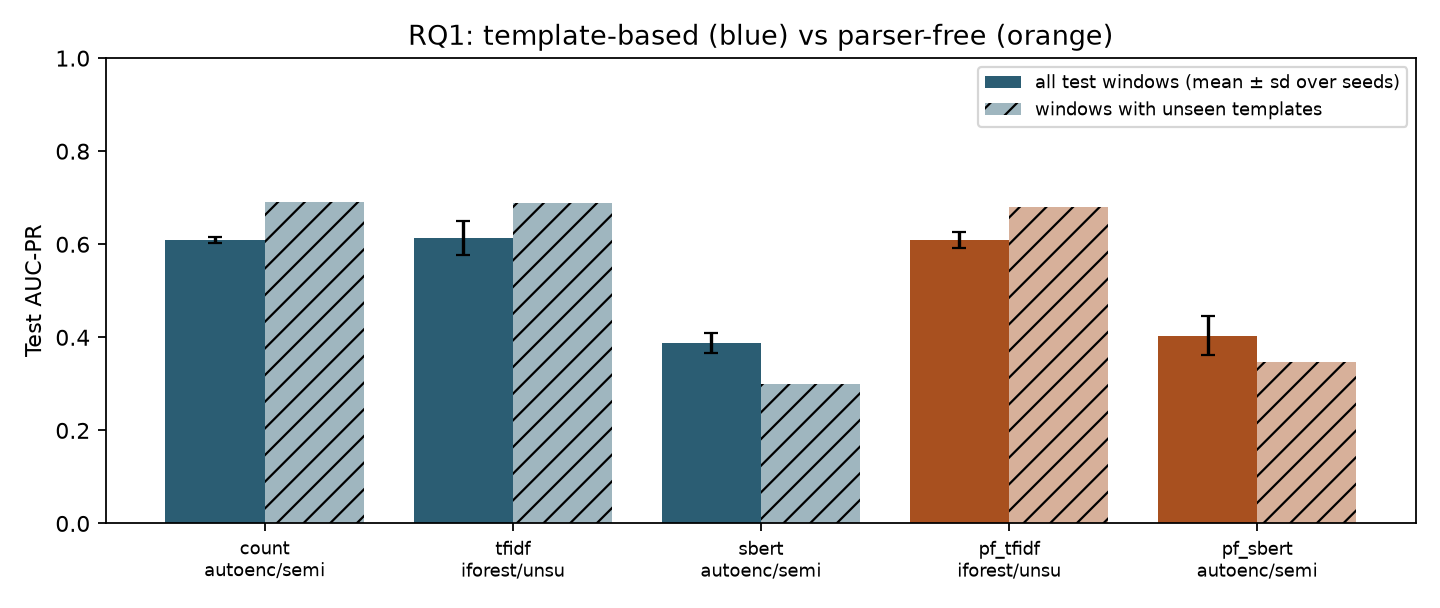

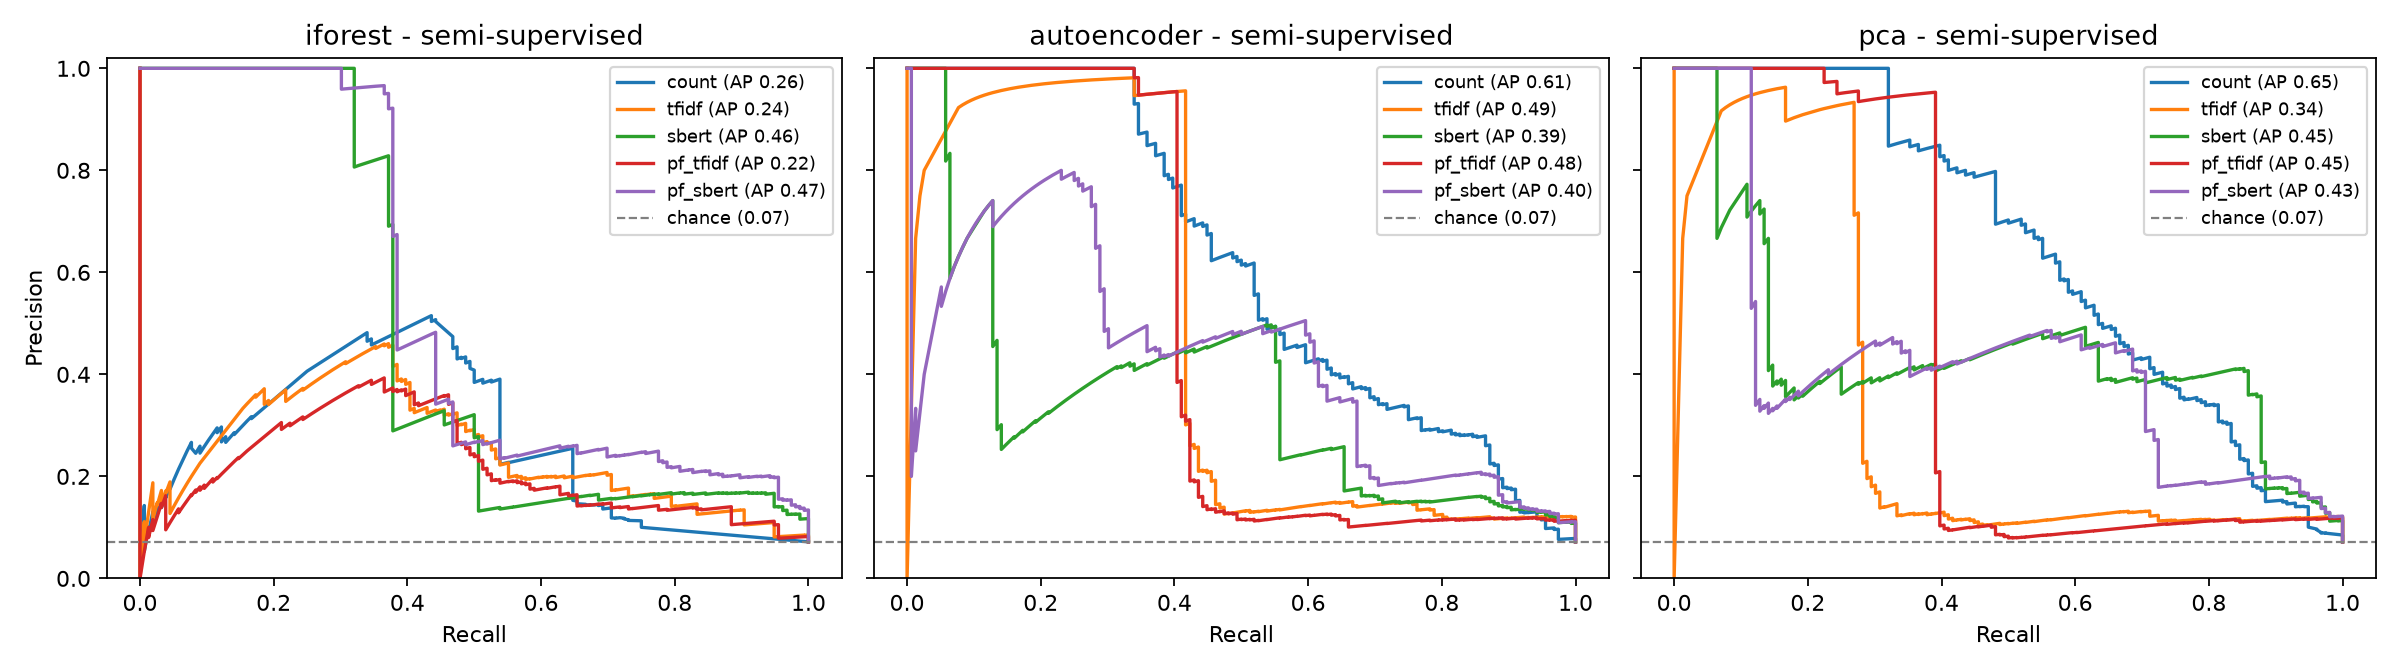

In [25]:
with timer("experiments (RQ1)"):
    results = run_experiments()
    plot_results(results, pd.read_parquet(RESULTS / "window_scores.parquet"))
cols = ["representation", "feature_set", "model", "regime", "val_auc_pr", "auc_pr", "auc_pr_sd", "auc_pr_novel",
        "f1", "false_alarms_per_day", "n_seeds"]
display(results.sort_values("val_auc_pr", ascending=False)[cols].round(3))
display(Image(FIGURES / "rq1_template_vs_parser_free.png"))
display(Image(FIGURES / "pr_curves_test.png"))

## 14. RQ2: data spit: chronological vs random splitting

In [26]:
def weekly_novelty() -> pd.DataFrame:
    df = lines[["ts", "cluster_id", "msg_id", "is_anomaly"]].copy()
    df["week"] = (df["ts"] - df["ts"].min()) // (7 * 86400)
    wk = df.groupby("week").agg(lines=("ts", "size"), anomaly_rate=("is_anomaly", "mean"))
    for key, name in (("cluster_id", "templates"), ("msg_id", "messages")):
        first_week = df.groupby(key)["week"].min()
        wk[f"{name}_first_seen"] = first_week.value_counts().reindex(wk.index, fill_value=0)
        wk[f"cumulative_{name}"] = wk[f"{name}_first_seen"].cumsum()
    return wk.reset_index()


def split_profile(sp_: np.ndarray) -> dict:
    C = counts["template"]
    unseen = np.asarray(C[sp_ == "train"].sum(axis=0)).ravel() == 0
    novel = np.asarray(C[:, unseen].sum(axis=1)).ravel() > 0
    test = sp_ == "test"
    return {"train_anomaly_rate": float(y[sp_ == "train"].mean()), "test_anomaly_rate": float(y[test].mean()),
            "test_windows_with_unseen_templates": float(novel[test].mean()),
            "templates_unseen_in_train": int(unseen.sum())}

In [27]:
def split_comparison() -> tuple[pd.DataFrame, pd.DataFrame]:
    rows, profiles = [], []
    for mode in ("chronological", "random"):
        for seed in SPLIT_SEEDS:
            sp_ = assign_split(len(meta), mode, seed)
            if mode == "random" or seed == SPLIT_SEEDS[0]:
                profiles.append({"split_mode": mode, "seed": seed, **split_profile(sp_)})
            val, test = sp_ == "val", sp_ == "test"
            t0 = time.perf_counter()
            for fs in FEATURE_SETS:
                C = counts[UNIT_OF[fs]]
                for model in SPLIT_MODELS:
                    if mode == "chronological" and model not in STOCHASTIC and seed != SPLIT_SEEDS[0]:
                        continue
                    for regime in (["supervised"] if model == "supervised_ref" else REGIMES):
                        set_seed(seed)
                        det = Detector(fs, model, seed)
                        if regime == "supervised":
                            det.fit(C[sp_ == "train"], y[sp_ == "train"])
                        else:
                            train = sp_ == "train"
                            det.fit(C[train & (y == 0) if regime == "semi_supervised" else train])
                        s_val, s_test = det.score(C[val]), det.score(C[test])
                        pred = s_test >= best_f1_threshold(y[val], s_val)
                        tp = int((pred & (y[test] == 1)).sum())
                        rows.append({"split_mode": mode, "seed": seed, "feature_set": fs,
                                     "representation": "parser-free" if fs in PARSER_FREE else "template",
                                     "model": model, "regime": regime,
                                     "test_auc_pr": average_precision_score(y[test], s_test),
                                     "test_f1": 2 * tp / max(int(pred.sum()) + int(y[test].sum()), 1)})
            log(f"{mode} split, seed {seed}: done in {time.perf_counter() - t0:.1f}s")
    return pd.DataFrame(rows), pd.DataFrame(profiles)

def summarise(runs: pd.DataFrame) -> pd.DataFrame:
    keys = ["feature_set", "representation", "model", "regime"]
    agg = runs.groupby(["split_mode"] + keys)[["test_auc_pr", "test_f1"]].agg(["mean", "std"])
    chrono, rnd = agg.loc["chronological"], agg.loc["random"]
    out = pd.DataFrame({
        "chrono_auc_pr": chrono[("test_auc_pr", "mean")],
        "chrono_auc_pr_sd": chrono[("test_auc_pr", "std")].fillna(0.0),
        "random_auc_pr_mean": rnd[("test_auc_pr", "mean")],
        "random_auc_pr_sd": rnd[("test_auc_pr", "std")].fillna(0.0),
        "chrono_f1": chrono[("test_f1", "mean")],
        "random_f1_mean": rnd[("test_f1", "mean")],
    })
    out["gap_auc_pr"] = out["random_auc_pr_mean"] - out["chrono_auc_pr"]
    noise = np.sqrt(out["chrono_auc_pr_sd"] ** 2 + out["random_auc_pr_sd"] ** 2)
    out["gap_exceeds_sd"] = (out["gap_auc_pr"].abs() > noise) & (out["gap_auc_pr"].abs() >= MIN_EFFECT)
    return out.reset_index()

In [28]:
def run_splits() -> pd.DataFrame:
    wk = weekly_novelty()
    wk.to_csv(RESULTS / "novelty_weekly.csv", index=False)
    fig, ax1 = plt.subplots(figsize=(9, 3.6))
    ax1.bar(wk["week"] - 0.2, wk["templates_first_seen"], 0.4, color="#2b5d73", label="templates first seen")
    ax1.bar(wk["week"] + 0.2, wk["messages_first_seen"], 0.4, color="#a8501f", label="masked messages first seen")
    ax1.set(xlabel="Week since start of log", ylabel="New units (log)", yscale="symlog")
    ax2 = ax1.twinx()
    ax2.plot(wk["week"], wk["anomaly_rate"], color="#444", marker="o", ms=3, lw=1, label="line anomaly rate")
    ax2.set_ylabel("Anomalous line fraction")
    fig.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.savefig(FIGURES / "novelty_weekly.png", dpi=160)
    plt.close(fig)

    runs, profiles = split_comparison()
    runs.to_csv(RESULTS / "splits_runs.csv", index=False)
    profiles.to_csv(RESULTS / "splits_profile.csv", index=False)
    summary = summarise(runs)
    summary.to_csv(RESULTS / "splits_summary.csv", index=False)

    panels = [(m, r) for m in SPLIT_MODELS for r in (["supervised"] if m == "supervised_ref" else REGIMES)]
    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.8), sharey=True)
    for ax, (model, regime) in zip(np.atleast_1d(axes), panels):
        d = summary[(summary["model"] == model) & (summary["regime"] == regime)].set_index("feature_set")
        d = d.reindex([f for f in FEATURE_SETS if f in d.index])
        x = np.arange(len(d))
        ax.bar(x - 0.2, d["chrono_auc_pr"], 0.4, yerr=d["chrono_auc_pr_sd"], capsize=3, color="#2b5d73",
               label="chronological")
        ax.bar(x + 0.2, d["random_auc_pr_mean"], 0.4, yerr=d["random_auc_pr_sd"], capsize=3, color="#a8501f",
               label=f"random (mean ± sd, {len(SPLIT_SEEDS)} seeds)")
        ax.set_xticks(x, d.index, fontsize=8)
        ax.set(ylim=(0, 1.05), title=f"{model} - {regime}")
        ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("Test AUC-PR")
    fig.tight_layout()
    fig.savefig(FIGURES / "rq2_chrono_vs_random.png", dpi=160)
    plt.close(fig)
    return summary

21:44:12 | chronological vs random splits (RQ2) ...
21:44:16 | chronological split, seed 42: done in 3.7s
21:44:19 | chronological split, seed 43: done in 2.8s
21:44:22 | chronological split, seed 44: done in 2.9s
21:44:26 | random split, seed 42: done in 3.5s
21:44:29 | random split, seed 43: done in 3.5s
21:44:33 | random split, seed 44: done in 3.6s
21:44:33 | chronological vs random splits (RQ2) done in 20.6s


,split_mode,seed,train_anomaly_rate,test_anomaly_rate,test_windows_with_unseen_templates,templates_unseen_in_train
0,chronological,42,0.079,0.072,0.748,105
1,random,42,0.074,0.066,0.003,17
2,random,43,0.073,0.072,0.002,24
3,random,44,0.072,0.070,0.005,32


,feature_set,representation,model,regime,chrono_auc_pr,chrono_auc_pr_sd,random_auc_pr_mean,random_auc_pr_sd,chrono_f1,random_f1_mean,gap_auc_pr,gap_exceeds_sd
0,count,template,iforest,semi_supervised,0.265,0.004,0.124,0.004,0.018,0.187,-0.141,True
1,count,template,iforest,unsupervised,0.550,0.020,0.459,0.017,0.500,0.473,-0.091,True
2,count,template,supervised_ref,supervised,0.695,0.000,0.966,0.004,0.713,0.971,0.271,True
3,pf_sbert,parser-free,iforest,semi_supervised,0.486,0.051,0.280,0.047,0.296,0.379,-0.206,True
4,pf_sbert,parser-free,iforest,unsupervised,0.467,0.024,0.303,0.048,0.232,0.358,-0.165,True
5,pf_sbert,parser-free,supervised_ref,supervised,0.992,0.000,0.997,0.002,0.957,0.970,0.004,False
6,pf_tfidf,parser-free,iforest,semi_supervised,0.217,0.009,0.137,0.017,0.391,0.298,-0.080,True
7,pf_tfidf,parser-free,iforest,unsupervised,0.622,0.008,0.398,0.059,0.618,0.450,-0.224,True
8,pf_tfidf,parser-free,supervised_ref,supervised,0.994,0.000,0.992,0.006,0.950,0.984,-0.003,False
9,sbert,template,iforest,semi_supervised,0.462,0.026,0.329,0.053,0.322,0.385,-0.133,True


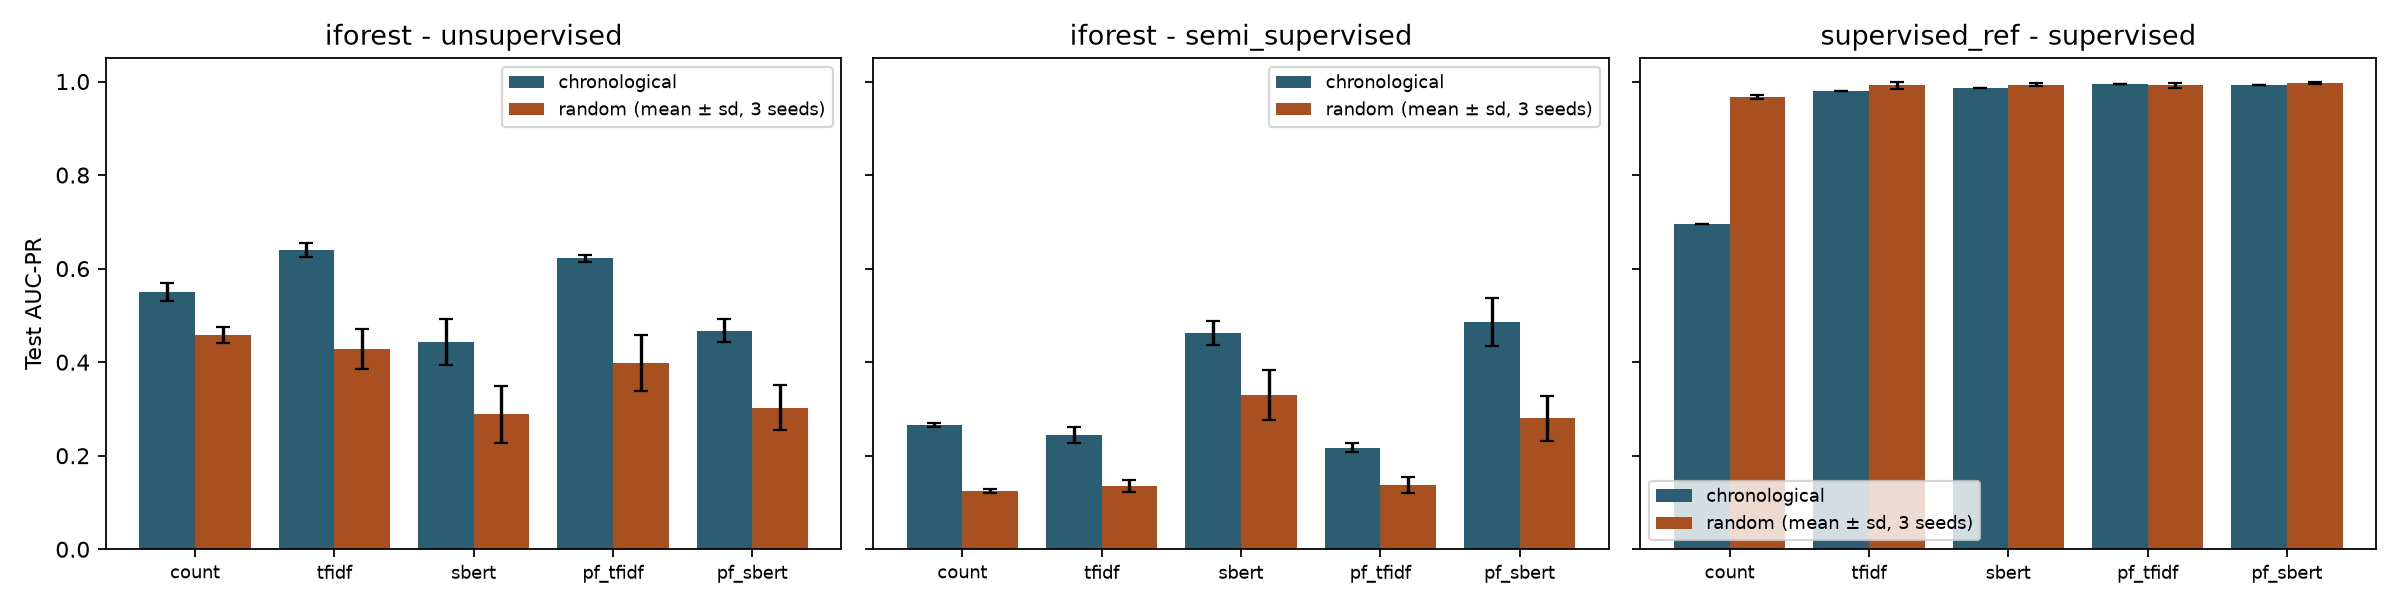

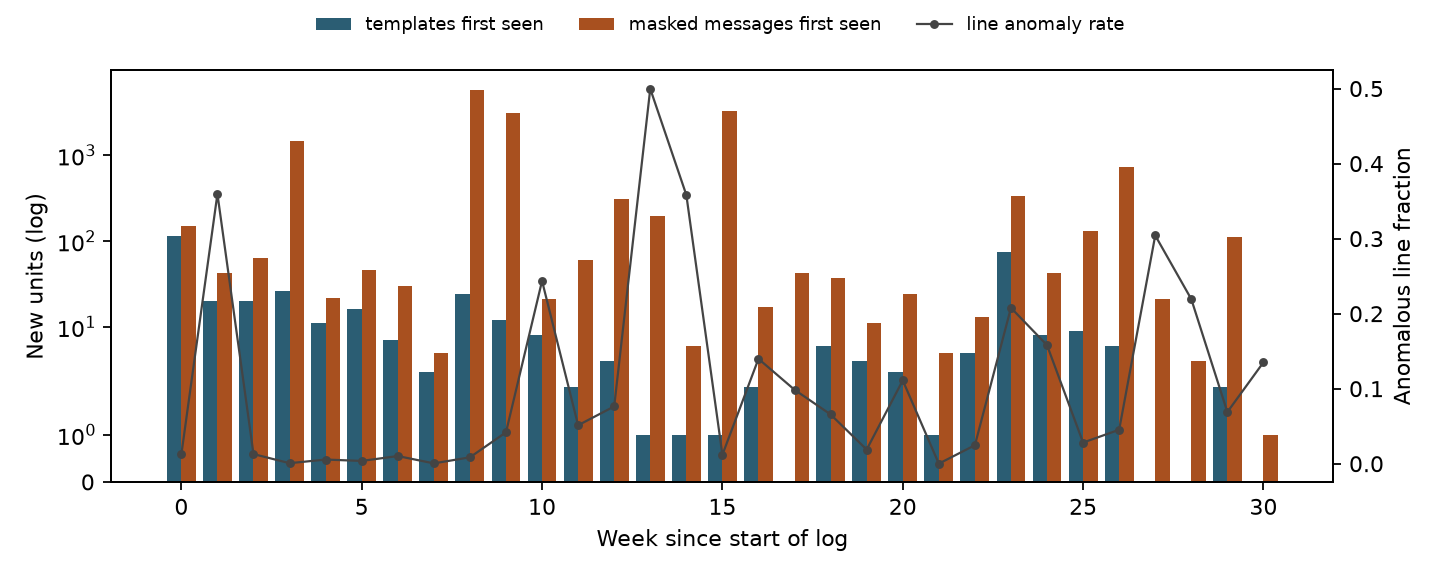

In [29]:
with timer("chronological vs random splits (RQ2)"):
    splits_summary = run_splits()
display(pd.read_csv(RESULTS / "splits_profile.csv").round(3))
display(splits_summary.round(3))
display(Image(FIGURES / "rq2_chrono_vs_random.png"))
display(Image(FIGURES / "novelty_weekly.png"))

In [30]:
def constant_feature_check() -> pd.DataFrame:
    test = split == "test"
    y_test = y[test]
    share = lambda v, cls: float(v[y_test == cls].mean()) if (y_test == cls).any() else np.nan
    rows = []
    for fs in FEATURE_SETS:
        C = counts[UNIT_OF[fs]]
        for regime in REGIMES:
            m = fit_mask(split, regime)
            transform = fit_features(fs, C[m])
            X_fit, X_test = transform(C[m]), transform(C[test])
            n_content = X_fit.shape[1] - (1 if NOVELTY_FEATURE else 0)
            const = X_fit[:, :n_content].std(axis=0) == 0
            uses = (np.abs(X_test[:, :n_content][:, const] - X_fit[0, :n_content][const]) > 1e-9).any(axis=1)
            novel = X_test[:, -1] > 0 if NOVELTY_FEATURE else np.zeros(len(X_test), bool)
            rows.append({"feature_set": fs, "regime": regime, "content_features": n_content,
                         "constant_in_training": int(const.sum()),
                         "anomalous_test_windows_using_them": share(uses, 1),
                         "normal_test_windows_using_them": share(uses, 0),
                         "anomalous_with_novelty_signal": share(novel, 1),
                         "normal_with_novelty_signal": share(novel, 0)})
    out = pd.DataFrame(rows)
    auc = results[results["model"] == "iforest"].set_index(["feature_set", "regime"])["auc_pr"]
    out["iforest_auc_pr"] = [auc.get((r.feature_set, r.regime), np.nan) for r in out.itertuples()]
    return out


constant_features = constant_feature_check()
constant_features.to_csv(RESULTS / "regime_constant_features.csv", index=False)
constant_features.round(3)

,feature_set,regime,content_features,constant_in_training,anomalous_test_windows_using_them,normal_test_windows_using_them,anomalous_with_novelty_signal,normal_with_novelty_signal,iforest_auc_pr
0,count,unsupervised,392,105,0.917,0.735,0.917,0.735,0.555
1,count,semi_supervised,392,221,1.000,0.735,1.000,0.735,0.265
2,tfidf,unsupervised,433,0,0.000,0.000,0.917,0.735,0.614
3,tfidf,semi_supervised,328,0,0.000,0.000,1.000,0.735,0.236
4,sbert,unsupervised,768,4,0.000,0.000,0.917,0.735,0.446
5,sbert,semi_supervised,768,4,0.000,0.000,1.000,0.735,0.460
6,pf_tfidf,unsupervised,575,0,0.000,0.000,0.923,0.747,0.610
7,pf_tfidf,semi_supervised,454,0,0.000,0.000,1.000,0.747,0.221
8,pf_sbert,unsupervised,768,4,0.000,0.000,0.923,0.747,0.438
9,pf_sbert,semi_supervised,768,4,0.000,0.000,1.000,0.747,0.472
